# 1. Email Spam Detection using TF-IDF + Logistic Regression
# Task: Classify emails as spam or ham using TF-IDF and logistic regression.

In [1]:
emails = [
    ("Win a FREE trip now!", "spam"),
    ("Please review the attached report", "ham"),
    ("Congratulations, you have won a lottery!", "spam"),
    ("Meeting scheduled at 10 AM tomorrow", "ham"),
    ("Free coupons waiting for you", "spam")
]


In [37]:
import pandas as pd
import numpy as np
import itertools
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix,accuracy_score,classification_report

df = pd.DataFrame(emails, columns=['content','lables'])
df
x=df['content']
y=df['lables']
vec=TfidfVectorizer()
tfidf=vec.fit_transform(x)

clf=LogisticRegression()
clf.fit(tfidf,y)
pred=clf.predict(tfidf)
score = accuracy_score(y, pred)
print("accuracy:   %0.3f" % score)

cm = confusion_matrix(y, pred)
print(cm)

accuracy:   1.000
[[2 0]
 [0 3]]


In [38]:
report=classification_report(y, pred)
print(report)

              precision    recall  f1-score   support

         ham       1.00      1.00      1.00         2
        spam       1.00      1.00      1.00         3

    accuracy                           1.00         5
   macro avg       1.00      1.00      1.00         5
weighted avg       1.00      1.00      1.00         5



In [42]:
print(x[[0]])
tf=vec.transform(x[[0]])
pred=clf.predict(tf)
print(pred)

0    Win a FREE trip now!
Name: content, dtype: object
['spam']


# 2. News Classification using CountVectorizer
# Task: Classify news into politics or sports.

In [44]:
news_data = [
    ("The prime minister addressed the nation.", "politics"),
    ("The team won the cricket match yesterday.", "sports"),
    ("New laws were introduced in the parliament.", "politics"),
    ("Football tournament starts next week.", "sports"),
    ("Government announces new tax reforms.", "politics"),
    ("The opposition leader criticized the budget plan.", "politics"),
    ("India defeated Australia in the final match.", "sports"),
    ("The president signed the healthcare bill.", "politics"),
    ("Tennis champion wins her sixth Grand Slam title.", "sports"),
    ("Cabinet approves new education policy.", "politics"),
    ("The hockey league season begins tomorrow.", "sports"),
    ("Parliament passes the environmental protection act.", "politics"),
    ("The coach announced the final team squad.", "sports"),
    ("Elections to be held in five states next month.", "politics"),
    ("Star player scores a hat-trick in the football match.", "sports"),
    ("Supreme Court hears plea on a on recent ordinance.", "politics")]


In [46]:
import pandas as pd
import numpy as np
import itertools
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix,accuracy_score,classification_report

df = pd.DataFrame(news_data, columns=['content','lables'])
df
x=df['content']
y=df['lables']
vec=CountVectorizer()
tfidf=vec.fit_transform(x)

clf=LogisticRegression()
clf.fit(tfidf,y)
pred=clf.predict(tfidf)
score = accuracy_score(y, pred)
print("accuracy:   %0.3f" % score)

cm = confusion_matrix(y, pred)
print(cm)
report=classification_report(y, pred)
print(report)

accuracy:   1.000
[[9 0]
 [0 7]]
              precision    recall  f1-score   support

    politics       1.00      1.00      1.00         9
      sports       1.00      1.00      1.00         7

    accuracy                           1.00        16
   macro avg       1.00      1.00      1.00        16
weighted avg       1.00      1.00      1.00        16



In [50]:
print(x[[1]])
tf=vec.transform(x[[1]])
pred=clf.predict(tf)
print(pred)

1    The team won the cricket match yesterday.
Name: content, dtype: object
['sports']


# 3. Product Review Sentiment using VADER
# Task: Perform sentiment analysis on product reviews.

In [4]:
reviews = [
    "Absolutely love this product, it works like a charm!",
    "Worst experience ever. Will never buy again.",
    "It's okay, not great but not bad either.",
    "Very satisfied with the quality!",
    "Disappointed. It stopped working in a week."
]


In [7]:
import pandas as pd
data = pd.DataFrame(reviews, columns=['reviews'])
data['reviews'][0]



'Absolutely love this product, it works like a charm!'

In [11]:
from nltk.sentiment.vader import SentimentIntensityAnalyzer
sid=SentimentIntensityAnalyzer()
##senti=sid.polarity_scores(data['reviews'][0])

data['Scores']=data['reviews'].apply(lambda commenttext: sid.polarity_scores(commenttext))
data['Compound']=data['Scores'].apply(lambda score_dict: score_dict['compound'])
data['Negative']=data['Scores'].apply(lambda score_dict: score_dict['neg'])
data['Positive']=data['Scores'].apply(lambda score_dict: score_dict['pos'])
data['Neutral']=data['Scores'].apply(lambda score_dict: score_dict['neu'])

data['comp_score']= data['Compound'].apply(lambda c: 'pos' if c >=0 else 'neg')


posneg=pd.DataFrame(data['comp_score'].value_counts())
print(posneg)

            count
comp_score       
pos             3
neg             2


# 4. Topic Modeling on Articles using LDA
# Task: Extract 2 topics from a list of article contents.

In [14]:
docs = [
    "Deep learning models can process images and videos.",
    "Neural networks are at the core of deep learning.",
    "Global warming affects the climate and ecosystems.",
    "Carbon emissions cause climate change.",
    "Convolutional neural networks perform well in vision tasks."
]
df = pd.DataFrame(docs,columns=['article'])
df

,article
0,Deep learning models can process images and vi...
1,Neural networks are at the core of deep learning.
2,Global warming affects the climate and ecosyst...
3,Carbon emissions cause climate change.
4,Convolutional neural networks perform well in ...


In [20]:


from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer(stop_words='english') 

dtm = vectorizer.fit_transform(df['article'])

from sklearn.decomposition import LatentDirichletAllocation
# Initialize and fit Topic Model
lda = LatentDirichletAllocation(n_components=2, random_state=42)
lda.fit(dtm)
feature_names = vectorizer.get_feature_names_out()
print(feature_names)



['affects' 'carbon' 'cause' 'change' 'climate' 'convolutional' 'core'
 'deep' 'ecosystems' 'emissions' 'global' 'images' 'learning' 'models'
 'networks' 'neural' 'perform' 'process' 'tasks' 'videos' 'vision'
 'warming']


In [22]:
for index,topic in enumerate(lda.components_):
    results=([feature_names[i] for i in topic.argsort()[-5:]])
    print(results)

['vision', 'convolutional', 'perform', 'networks', 'neural']
['process', 'models', 'climate', 'learning', 'deep']


#  5. Word Cloud for Movie Reviews
# Task: Visualize frequently used words in movie reviews.

In [14]:
movie_reviews = """
The movie was fantastic! Acting was brilliant and the story was well-written.
Amazing visuals and a gripping plot.
It was a bit slow in the middle, but overall a great movie experience.
"""


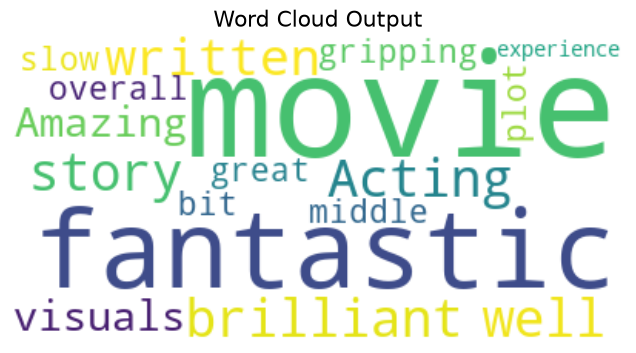

In [1]:
from wordcloud import WordCloud
import pandas as pd
import matplotlib.pyplot as plt

text = """
The movie was fantastic! Acting was brilliant and the story was well-written.
Amazing visuals and a gripping plot.
It was a bit slow in the middle, but overall a great movie experience.
"""

# Generate word cloud
wc = WordCloud(background_color='white').generate(text)

# Display the word cloud
plt.figure(figsize=(8, 4))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title("Word Cloud Output", fontsize=16)
plt.show()